# Завдання: Інтелектуальне збагачення Excel-даних

Створіть систему, яка:

1. Приймає Excel-файл і текстовий опис завдання

2. Аналізує структуру даних і визначає, яка інформація потрібна

3. Шукає необхідні дані в інтернеті (якщо потрібно)

4. Додає нові колонки зі знайденою інформацією

5. Зберігає збагачений файл


## 1. Архітектура та реалізація AI-системи (LangGraph)

Система — послідовний граф `load_and_validate` → `plan_enrichment` → `enrich_rows` → `save_and_verify`; публічний інтерфейс — `process_excel(file_path, task_description)`.

* **План від LLM** (`EnrichmentPlan`): які колонки заповнити (одна чи кілька), чи потрібен вебпошук, шаблон запиту + альтернативний шаблон для перевірки. План валідується в коді (назви колонок, плейсхолдери).
* **Пошук** — Tavily; **витягування** — LLM виписує кандидатів по кожному джерелу, а остаточне значення обирає код (кластер збіжних значень ±10%, а не перше, що сказала модель). Значення іншого показника (напр. автомобільний маршрут замість прямої) відкидаються.
* **Економія запитів:** дедуплікація однакових запитів, JSON-кеш (запис пакетами), другий пошук — лише якщо джерела суперечать одне одному або нічого не знайдено.
* **Паралельність:** `ThreadPoolExecutor` (`MAX_WORKERS`).
* **Помилки:** зупинка при невірному ключі/вичерпаному ліміті, повідомлення з номерами рядків Excel, порожня клітинка, якщо даних немає.
* **Збереження структури:** вже заповнені клітинки та інші колонки не змінюються (перевіряється перед записом).

> Ключі беруться з Colab Secrets (`OPENROUTER_API_KEY`, `TAVILY_API_KEY`) або зі змінних середовища; у коді їх немає. Модель змінюється через `LLM_MODEL`.


In [1]:
!pip install -q langchain langchain-core langchain-openai langgraph pydantic pandas openpyxl requests

langgraph: 1.2.19


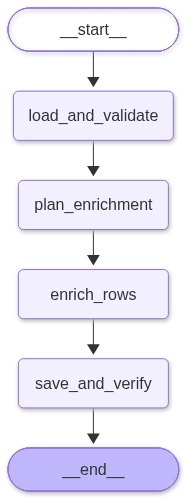

In [2]:
import hashlib
import json
import os
import statistics
import string
import re
import threading
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from functools import lru_cache
from importlib.metadata import version
from pathlib import Path
from typing import Any, Dict, List, Literal, Optional, Tuple, TypedDict

import pandas as pd
import requests
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

print("langgraph:", version("langgraph"))

# ==============================================================================
# 1. НАЛАШТУВАННЯ
# ==============================================================================

AUTHOR_PREFIX = "Svitlana_Stremedlovska"  # префікс для імені збагаченого файлу
LLM_MODEL = os.getenv("LLM_MODEL", "~google/gemini-flash-latest")
MAX_WORKERS = 8  # кількість паралельних потоків
SOFT_ROW_LIMIT = 1000  # орієнтир із вимог; більші файли обробляються з попередженням
NUMERIC_TOLERANCE = 0.10  # допуск ±10% для порівняння числових кандидатів
CACHE_VERSION = "v2"  # зміна версії анулює старі записи кешу
TAVILY_URL = "https://api.tavily.com/search"


def _get_secret(name: str) -> Optional[str]:
    """Читає ключ із Colab Secrets або зі змінної середовища (без падіння, якщо його нема)."""
    value = None
    try:
        from google.colab import userdata

        try:
            value = userdata.get(name)
        except Exception:  # секрету немає в Colab
            value = None
    except ImportError:  # запуск поза Colab
        pass
    value = value or os.getenv(name)
    return value.strip() if value else None


def check_credentials() -> None:
    missing = [n for n in ("OPENROUTER_API_KEY", "TAVILY_API_KEY") if not _get_secret(n)]
    if missing:
        raise RuntimeError(
            f"Не знайдено ключі: {', '.join(missing)}. Додайте їх у Colab Secrets "
            "або змінні середовища (самі ключі в код не вписуйте)."
        )


class FatalAPIError(RuntimeError):
    """Помилка, після якої продовжувати немає сенсу (невірний ключ, вичерпаний ліміт)."""


@lru_cache(maxsize=1)
def get_llm() -> ChatOpenAI:
    """Створює LLM-клієнт при першому використанні (ключі беруться під час виклику)."""
    return ChatOpenAI(
        model=LLM_MODEL,
        temperature=0,
        api_key=_get_secret("OPENROUTER_API_KEY"),
        base_url="https://openrouter.ai/api/v1",
        max_retries=3,  # автоматичні повтори при 429/5xx
        timeout=60,
    )


# ==============================================================================
# 2. СТРУКТУРИ ДАНИХ (PYDANTIC ТА СТАН ГРАФА)
# ==============================================================================


class ColumnTask(BaseModel):
    """План заповнення ОДНІЄЇ цільової колонки."""

    target_column: str = Field(
        description="Точна назва колонки для запису (існуюча порожня колонка або нова)."
    )
    value_type: Literal["int", "float", "str"] = Field(
        description="Тип результату: 'int' — цілі числа, 'float' — дробові, 'str' — текст."
    )
    context_columns: List[str] = Field(
        description="Колонки таблиці, що однозначно описують об'єкт пошуку в кожному рядку."
    )
    search_query_template: str = Field(
        description=(
            "Шаблон пошукового запиту АНГЛІЙСЬКОЮ з точними назвами колонок у фігурних дужках, "
            "напр.: '{Capital_From} {Country_From} to {Capital_To} {Country_To} straight line distance km'."
        )
    )
    alt_query_template: str = Field(
        description=(
            "Альтернативне, інакше сформульоване формулювання того ж запиту (інші слова, "
            "інший термін), що використовується лише для перевірки результату."
        )
    )
    extraction_instruction: str = Field(
        description="Яке саме значення витягти з результатів пошуку та в яких одиницях."
    )


class EnrichmentPlan(BaseModel):
    """Універсальний план збагачення таблиці, сформований LLM."""

    requires_web_search: bool = Field(
        description=(
            "True, якщо для відповіді потрібні зовнішні факти з інтернету. "
            "False, якщо значення можна отримати з даних самого рядка (форматування, "
            "перетворення, обчислення, переклад тощо)."
        )
    )
    tasks: List[ColumnTask] = Field(
        description="По одному елементу на кожну колонку, яку потрібно заповнити."
    )


class Candidate(BaseModel):
    """Одне значення-кандидат, знайдене в конкретному джерелі."""

    value: str = Field(description="Значення без одиниць вимірювання (напр. '8849' або 'Tokyo').")
    matches_request: bool = Field(
        description=(
            "True, лише якщо це саме той показник, який просить користувач. "
            "False для іншого показника (напр. відстань автомобілем замість прямої, "
            "інший об'єкт або однойменне місце)."
        )
    )
    source: str = Field(description="Короткий опис джерела (назва сторінки або домен).")


class ExtractedValues(BaseModel):
    """Список кандидатів, знайдених у результатах пошуку."""

    candidates: List[Candidate] = Field(
        default_factory=list,
        description="Порожній список, якщо достовірних даних у результатах немає.",
    )


class EnrichmentState(TypedDict):
    """Стан графа LangGraph."""

    file_path: str
    output_path: str
    task_description: str

    df: Optional[pd.DataFrame]
    original_df: Optional[pd.DataFrame]
    sheet_name: str
    other_sheets: Dict[str, pd.DataFrame]
    original_columns: List[str]
    plan: Optional[EnrichmentPlan]
    stats: Dict[str, Any]
    errors: List[str]
    warnings: List[str]


# ==============================================================================
# 3. КЕШ ТА ПОШУКОВИЙ КЛІЄНТ (TAVILY)
# ==============================================================================


class DiskCache:
    """Потокобезпечний JSON-кеш. Записує на диск пакетами, а не після кожного запиту."""

    def __init__(self, cache_file: str = "enrichment_cache.json", flush_every: int = 25):
        self.cache_path = Path(cache_file)
        self._lock = threading.Lock()
        self._flush_every = flush_every
        self._unsaved = 0
        self._data: Dict[str, Any] = self._load()

    def _load(self) -> Dict[str, Any]:
        if self.cache_path.exists():
            try:
                return json.loads(self.cache_path.read_text(encoding="utf-8"))
            except Exception:
                return {}  # пошкоджений кеш просто ігноруємо
        return {}

    def get(self, key: str) -> Optional[Any]:
        with self._lock:
            return self._data.get(key)

    def set(self, key: str, value: Any) -> None:
        with self._lock:
            self._data[key] = value
            self._unsaved += 1
            if self._unsaved >= self._flush_every:
                self._write()

    def flush(self) -> None:
        with self._lock:
            if self._unsaved:
                self._write()

    def _write(self) -> None:
        tmp = self.cache_path.with_suffix(".tmp")
        tmp.write_text(json.dumps(self._data, ensure_ascii=False, indent=2), encoding="utf-8")
        tmp.replace(self.cache_path)  # атомарна заміна: кеш не буде напівзаписаним
        self._unsaved = 0


CACHE = DiskCache()


def tavily_search(
    query: str, max_retries: int = 3, timeout: int = 20, search_depth: str = "basic"
) -> Dict[str, Any]:
    """Вебпошук через Tavily. Повторює спроби при тимчасових збоях (429, 5xx, мережа)."""
    headers = {
        "Authorization": f"Bearer {_get_secret('TAVILY_API_KEY')}",
        "Content-Type": "application/json",
    }
    payload = {
        "query": query,
        "search_depth": search_depth,  # basic = 1 кредит, advanced = 2 кредити
        "include_answer": True,
        "max_results": 5,
    }

    last_error: Any = None
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.post(TAVILY_URL, headers=headers, json=payload, timeout=timeout)
        except requests.RequestException as exc:  # таймаут, обрив з'єднання
            last_error = exc
        else:
            code = response.status_code
            if code in (401, 403):
                raise FatalAPIError(f"Tavily відхилив ключ (HTTP {code}). Перевірте TAVILY_API_KEY.")
            if code in (402, 432, 433):
                raise FatalAPIError(f"Вичерпано ліміт або тариф Tavily (HTTP {code}).")
            if code == 429 or code >= 500:  # тимчасова помилка — пробуємо ще
                last_error = f"HTTP {code}"
            elif code >= 400:  # інші 4xx повторювати марно
                raise RuntimeError(f"Tavily повернув HTTP {code}: {response.text[:200]}")
            else:
                return response.json()
        if attempt < max_retries:
            time.sleep(2 ** (attempt - 1))  # 1 с, 2 с, ...

    raise RuntimeError(f"Tavily недоступний після {max_retries} спроб ('{query}'): {last_error}")


# ==============================================================================
# 4. ДОПОМІЖНІ ФУНКЦІЇ
# ==============================================================================


def cast_extracted_value(raw_value: Optional[str], value_type: str) -> Optional[Any]:
    """Приводить рядок до int / float / str. Повертає None, якщо значення непридатне."""
    if raw_value is None:
        return None
    text = str(raw_value).strip()
    if not text or text.lower() in {"none", "null", "n/a", "unknown", "nan", "not found"}:
        return None

    if value_type in ("int", "float"):
        cleaned = re.sub(r"(?<=\d)[\s,](?=\d{3}\b)", "", text)  # 8,849 -> 8849
        match = re.search(r"-?\d+(?:[.,]\d+)?", cleaned)
        if not match:
            return None
        num = float(match.group(0).replace(",", "."))
        return int(round(num)) if value_type == "int" else num
    return text


def _rel_diff(value: float, reference: float) -> float:
    """Відносна різниця між двома числами."""
    return abs(value - reference) / abs(reference) if reference else abs(value)


def aggregate_candidates(
    candidates: List[Candidate], value_type: str, tolerance: float = NUMERIC_TOLERANCE
) -> Tuple[Optional[Any], bool]:
    """
    Обирає остаточне значення з кандидатів різних джерел.

    Повертає (значення, чи узгоджене). Значення «узгоджене», якщо щонайменше два
    незалежні джерела збігаються (для чисел — у межах допуску).
    """
    values = []
    for cand in candidates:
        if not cand.matches_request:
            continue  # значення іншого показника (напр. автомобільний маршрут)
        parsed = cast_extracted_value(cand.value, value_type)
        if parsed is not None:
            values.append(parsed)
    if not values:
        return None, False

    if value_type in ("int", "float"):
        values.sort()
        # шукаємо найбільший кластер значень, що близькі одне до одного
        centre = max(values, key=lambda v: sum(_rel_diff(w, v) <= tolerance for w in values))
        cluster = [w for w in values if _rel_diff(w, centre) <= tolerance]
        consistent = len(cluster) >= 2
        result = statistics.median(cluster if consistent else values)
        # float(f"{x:.10g}") прибирає артефакти на кшталт 214.58499999999998
        return (int(round(result)) if value_type == "int" else float(f"{result:.10g}")), consistent

    counts = Counter(v.casefold() for v in values)
    top, top_count = counts.most_common(1)[0]
    result = next(v for v in values if v.casefold() == top)
    return result, top_count >= 2


def _template_fields(template: str) -> List[str]:
    """Повертає імена полів, використаних у шаблоні запиту ({Col})."""
    try:
        names = [name for _, name, _, _ in string.Formatter().parse(template) if name]
    except ValueError:
        return ["<некоректний шаблон>"]
    return [re.split(r"[.\[]", name)[0] for name in names]


def format_query(template: str, row_dict: Dict[str, str], fallback_columns: List[str]) -> str:
    """Підставляє значення рядка в шаблон. При помилці формує запит зі значень колонок."""
    try:
        return " ".join(template.format(**row_dict).split())
    except (KeyError, IndexError, ValueError, AttributeError):
        return " ".join(row_dict.get(c, "") for c in fallback_columns if row_dict.get(c))


def _is_blank(value: Any) -> bool:
    return pd.isna(value) or str(value).strip() == ""


def _is_auth_error(exc: Exception) -> bool:
    """Розпізнає помилки авторизації LLM-провайдера (невірний ключ / немає доступу)."""
    return type(exc).__name__ in {"AuthenticationError", "PermissionDeniedError"}


def normalize_plan(plan: EnrichmentPlan, df: pd.DataFrame) -> EnrichmentPlan:
    """Перевіряє й виправляє план LLM: назви колонок, плейсхолдери шаблонів, дублікати."""
    columns = [str(c) for c in df.columns]
    by_norm = {c.strip().casefold(): c for c in columns}
    tasks, seen = [], set()

    for task in plan.tasks:
        target = by_norm.get(task.target_column.strip().casefold(), task.target_column.strip())
        if not target or target in seen:
            continue
        seen.add(target)
        task.target_column = target

        task.context_columns = [
            by_norm[c.strip().casefold()]
            for c in task.context_columns
            if c.strip().casefold() in by_norm and by_norm[c.strip().casefold()] != target
        ]
        if not task.context_columns:
            task.context_columns = [c for c in columns if c != target]

        if not set(_template_fields(task.search_query_template)) <= set(columns):
            placeholders = " ".join("{%s}" % c for c in task.context_columns)
            task.search_query_template = f"{placeholders} {target}"
        if not set(_template_fields(task.alt_query_template)) <= set(columns):
            task.alt_query_template = ""  # без альтернативного запиту
        tasks.append(task)

    if not tasks:
        raise ValueError("LLM не визначила жодної колонки для заповнення. Уточніть завдання.")
    plan.tasks = tasks
    return plan


# ==============================================================================
# 5. ПОШУК І ВИТЯГУВАННЯ ЗНАЧЕННЯ ДЛЯ ОДНОГО ОБ'ЄКТА
# ==============================================================================


@lru_cache(maxsize=1)
def get_planner():
    return get_llm().with_structured_output(EnrichmentPlan)


@lru_cache(maxsize=1)
def get_extractor():
    return get_llm().with_structured_output(ExtractedValues)


def extract_candidates(
    task_description: str, task: ColumnTask, query: str, context_text: str, from_web: bool
) -> List[Candidate]:
    """Просить LLM виписати кандидатів значення (по одному на кожне джерело)."""
    source_rule = (
        "Використовуй ЛИШЕ наведені результати пошуку, не додавай значень зі своїх знань.\n"
        if from_web
        else "Значення визначай із наведених даних рядка (за потреби — із загальних знань).\n"
    )
    prompt = (
        f"Оригінальний запит користувача: {task_description}\n"
        f"Колонка для заповнення: {task.target_column} (тип: {task.value_type})\n"
        f"Інструкція екстракції: {task.extraction_instruction}\n"
        f"Запит: {query}\n\n"
        f"{context_text}\n\n"
        "Правила:\n"
        f"1. {source_rule}"
        "2. Для КОЖНОГО незалежного джерела, де є відповідь, додай окремого кандидата.\n"
        "3. matches_request=True лише для того показника, що просить користувач. Пряма відстань "
        "(по повітрю, great-circle) — це НЕ відстань автомобілем чи залізницею; висота над рівнем "
        "моря — це НЕ відносна висота чи довжина маршруту.\n"
        "4. Значення пиши числом без одиниць, переведеним у потрібні одиниці (милі→км, фути→м).\n"
        "5. Якщо достовірних даних немає — поверни порожній список."
    )
    extracted: Optional[ExtractedValues] = get_extractor().invoke(prompt)
    return list(extracted.candidates) if extracted else []


def _search_candidates(
    query: str, task_description: str, task: ColumnTask, depth: str = "basic"
) -> List[Candidate]:
    """Один пошуковий запит + екстракція кандидатів."""
    data = tavily_search(query, search_depth=depth)
    snippets = [f"- {r.get('title', '')}: {r.get('content', '')}" for r in data.get("results", [])]
    answer = data.get("answer") or ""
    context = (
        f"Автоматична відповідь пошуковика (менш надійна): {answer}\n\n"
        "Результати пошуку:\n" + "\n".join(snippets)
    )
    return extract_candidates(task_description, task, query, context, from_web=True)


def resolve_entity(
    task: ColumnTask,
    query: str,
    alt_query: str,
    task_description: str,
    requires_search: bool,
    row_context: Dict[str, str],
) -> Dict[str, Any]:
    """
    Знаходить значення для одного унікального об'єкта.

    Економія запитів: один пошук, якщо кандидати узгоджені; другий (альтернативний)
    запит — лише коли джерела суперечать одне одному або нічого не знайдено.
    """
    cache_key = hashlib.sha256(
        f"{CACHE_VERSION}|{LLM_MODEL}|{task.target_column}|{task.value_type}|"
        f"{task_description}|{query}".encode("utf-8")
    ).hexdigest()

    cached = CACHE.get(cache_key)
    if cached is not None and cached.get("consistent", True):  # сумнівні записи перераховуємо
        return {
            "value": cached["value"],
            "consistent": cached.get("consistent", True),
            "from_cache": True,
            "searches": 0,
            "error": None,
        }

    searches = 0
    try:
        if requires_search:
            candidates = _search_candidates(query, task_description, task)
            searches += 1
            value, consistent = aggregate_candidates(candidates, task.value_type)
            if (value is None or not consistent) and alt_query and alt_query != query:
                candidates += _search_candidates(alt_query, task_description, task)
                searches += 1
                value, consistent = aggregate_candidates(candidates, task.value_type)
            if value is not None and not consistent:
                # джерела досі суперечать: фінальна спроба — глибокий пошук (2 кредити, рідкісний випадок)
                candidates += _search_candidates(query, task_description, task, depth="advanced")
                searches += 1
                value, consistent = aggregate_candidates(candidates, task.value_type)
        else:
            context = f"Дані рядка таблиці: {json.dumps(row_context, ensure_ascii=False)}"
            candidates = extract_candidates(task_description, task, query, context, from_web=False)
            value, _ = aggregate_candidates(candidates, task.value_type)
            consistent = True
    except FatalAPIError:
        raise
    except Exception as exc:
        if _is_auth_error(exc):
            raise FatalAPIError(f"LLM-провайдер відхилив ключ: {exc}") from exc
        return {"value": None, "consistent": False, "from_cache": False, "searches": searches,
                "error": f"{type(exc).__name__}: {exc}"}

    if value is None:
        return {"value": None, "consistent": False, "from_cache": False, "searches": searches,
                "error": "достовірного значення в результатах пошуку не знайдено"}

    if consistent:  # сумнівні значення не кешуємо, щоб наступний запуск спробував ще раз
        CACHE.set(cache_key, {"query": query, "value": value, "consistent": True})
    return {"value": value, "consistent": consistent, "from_cache": False,
            "searches": searches, "error": None}


# ==============================================================================
# 6. ВУЗЛИ ГРАФА LANGGRAPH
# ==============================================================================


def load_and_validate(state: EnrichmentState) -> dict:
    """Вузол 1: читання Excel і перевірка вхідних даних."""
    path = Path(state["file_path"])
    if not path.exists():
        raise FileNotFoundError(f"Вхідний файл не знайдено: {path}")
    if path.suffix.lower() not in {".xlsx", ".xlsm", ".xls"}:
        raise ValueError(f"Непідтримуваний формат: {path.suffix}. Очікується .xlsx / .xlsm / .xls")

    try:
        sheets = pd.read_excel(path, sheet_name=None)  # усі аркуші
    except Exception as exc:
        raise ValueError(f"Не вдалося прочитати Excel-файл {path.name}: {exc}") from exc

    sheet_name = next(iter(sheets))
    df = sheets.pop(sheet_name)  # збагачуємо перший аркуш, решту зберігаємо без змін
    if df.empty:
        raise ValueError(f"Перший аркуш файлу {path.name} порожній (0 рядків).")

    warnings = []
    if len(df) > SOFT_ROW_LIMIT:
        warnings.append(
            f"Файл містить {len(df)} рядків (орієнтир — {SOFT_ROW_LIMIT}); обробка може тривати довше."
        )
    if sheets:
        warnings.append(f"Збагачено лише перший аркуш '{sheet_name}'; інші аркуші збережено як є.")

    return {
        "df": df,
        "original_df": df.copy(),
        "sheet_name": str(sheet_name),
        "other_sheets": sheets,
        "original_columns": df.columns.tolist(),
        "errors": [],
        "warnings": warnings,
        "stats": {"total_rows": len(df)},
    }


def plan_enrichment(state: EnrichmentState) -> dict:
    """Вузол 2: LLM аналізує таблицю й завдання та складає план (які колонки, які запити)."""
    check_credentials()
    df = state["df"]
    schema_info = {str(col): str(dtype) for col, dtype in df.dtypes.items()}
    empty_info = {str(c): int(df[c].isna().sum()) for c in df.columns if df[c].isna().any()}
    sample_rows = df.head(3).fillna("").astype(str).to_dict(orient="records")

    prompt = (
        "Ти — архітектор систем збагачення табличних даних.\n"
        "Проаналізуй структуру Excel-таблиці, приклади рядків та завдання користувача.\n\n"
        f"Завдання користувача: {state['task_description']}\n"
        f"Колонки та типи: {json.dumps(schema_info, ensure_ascii=False)}\n"
        f"Кількість порожніх клітинок у колонках: {json.dumps(empty_info, ensure_ascii=False)}\n"
        f"Приклади перших рядків: {json.dumps(sample_rows, ensure_ascii=False)}\n\n"
        "Сформуй план:\n"
        "1. requires_web_search — чи потрібні факти з інтернету (False для перетворень даних рядка).\n"
        "2. tasks — по одному елементу на КОЖНУ колонку, яку треба заповнити (одну або кілька). "
        "Якщо користувач називає існуючу колонку — вкажи її назву точно так само.\n"
        "3. context_columns — колонки, що описують об'єкт пошуку (назви міст РАЗОМ із країнами, "
        "щоб уникнути неоднозначності).\n"
        "4. search_query_template — запит англійською з точними назвами колонок у {фігурних дужках}, "
        "напр.: '{Capital_From} {Country_From} to {Capital_To} {Country_To} straight line distance km' "
        "або '{Mountain} {Country} mountain elevation above sea level meters'.\n"
        "5. alt_query_template — той самий зміст, але інші слова (напр. 'great-circle distance between "
        "{Capital_From} and {Capital_To} in kilometers').\n"
        "6. extraction_instruction — яке саме значення і в яких одиницях брати зі сніпетів.\n"
        "7. value_type — int / float / str."
    )

    try:
        plan = get_planner().invoke(prompt)
        plan = normalize_plan(plan, df)
    except (FatalAPIError, ValueError):
        raise
    except Exception as exc:
        if _is_auth_error(exc):
            raise FatalAPIError(f"LLM-провайдер відхилив ключ: {exc}") from exc
        raise RuntimeError(f"Не вдалося скласти план збагачення: {type(exc).__name__}: {exc}") from exc
    return {"plan": plan}


def enrich_rows(state: EnrichmentState) -> dict:
    """Вузол 3: дедуплікація, паралельний пошук і запис значень у цільові колонки."""
    df = state["df"].copy()
    plan: EnrichmentPlan = state["plan"]
    errors = list(state.get("errors", []))
    warnings = list(state.get("warnings", []))

    for task in plan.tasks:
        if task.target_column not in df.columns:
            df[task.target_column] = None
        df[task.target_column] = df[task.target_column].astype("object")  # безпечно для чисел і тексту

    # --- збираємо унікальні завдання: (колонка, запит) -> рядки, яким він потрібен
    per_col = {t.target_column: {"to_fill": 0, "filled": 0} for t in plan.tasks}
    jobs: Dict[Tuple[int, str], Dict[str, Any]] = {}
    for t_idx, task in enumerate(plan.tasks):
        for idx, row in df.iterrows():
            if not _is_blank(row[task.target_column]):
                continue  # існуючі значення не чіпаємо
            row_dict = {str(c): ("" if pd.isna(v) else str(v).strip()) for c, v in row.items()}
            if not any(row_dict.get(c) for c in task.context_columns):
                per_col[task.target_column]["to_fill"] += 1
                errors.append(
                    f"Колонка '{task.target_column}', рядок Excel {idx + 2}: у колонках "
                    f"{task.context_columns} немає значень — рядок пропущено без запиту."
                )
                continue
            if plan.requires_web_search:
                query = format_query(task.search_query_template, row_dict, task.context_columns)
                alt = format_query(task.alt_query_template, row_dict, []) if task.alt_query_template else ""
                context = row_dict
            else:
                context = {c: row_dict.get(c, "") for c in task.context_columns}
                query = json.dumps(context, ensure_ascii=False, sort_keys=True)
                alt = ""
            if not query:
                per_col[task.target_column]["to_fill"] += 1
                errors.append(f"Колонка '{task.target_column}', рядок Excel {idx + 2}: порожній контекст для пошуку.")
                continue
            job = jobs.setdefault((t_idx, query), {"task": task, "alt": alt, "context": context, "rows": []})
            job["rows"].append(idx)

    # --- паралельне виконання
    abort = threading.Event()
    totals = {"cache_hits": 0, "searches": 0}
    fatal: Optional[str] = None

    def run(job_key: Tuple[int, str]) -> Dict[str, Any]:
        if abort.is_set():
            return {"skipped": True}
        job = jobs[job_key]
        return resolve_entity(job["task"], job_key[1], job["alt"], state["task_description"],
                              plan.requires_web_search, job["context"])

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {executor.submit(run, key): key for key in jobs}
        for future in as_completed(futures):
            key = futures[future]
            job = jobs[key]
            col = job["task"].target_column
            excel_rows = ", ".join(str(i + 2) for i in job["rows"])
            per_col[col]["to_fill"] += len(job["rows"])
            try:
                res = future.result()
            except FatalAPIError as exc:
                fatal = fatal or str(exc)
                abort.set()
                for pending in futures:
                    pending.cancel()
                continue
            except Exception as exc:  # непередбачена помилка одного завдання не валить решту
                errors.append(f"Колонка '{col}', рядки Excel {excel_rows}: {type(exc).__name__}: {exc}")
                continue
            if res.get("skipped"):
                continue

            totals["cache_hits"] += int(res["from_cache"])
            totals["searches"] += res["searches"]
            if res["error"]:
                errors.append(f"Колонка '{col}', рядки Excel {excel_rows} ('{key[1]}'): {res['error']}.")
                continue
            if not res["consistent"]:
                warnings.append(
                    f"Колонка '{col}', рядки Excel {excel_rows}: значення {res['value']} не підтверджено "
                    "двома узгодженими джерелами (одне джерело або суперечливі дані) — перевірте вручну."
                )
            for idx in job["rows"]:
                df.at[idx, col] = res["value"]
            per_col[col]["filled"] += len(job["rows"])

    CACHE.flush()
    if fatal:
        raise RuntimeError(f"Обробку зупинено: {fatal}")

    # --- типи колонок (числові — лише якщо всі значення справді числа)
    for task in plan.tasks:
        col = task.target_column
        if task.value_type in ("int", "float"):
            try:
                df[col] = pd.to_numeric(df[col], errors="raise")
            except (ValueError, TypeError):
                continue
            if task.value_type == "int" and df[col].notna().any() and (df[col].dropna() % 1 == 0).all():
                df[col] = df[col].astype("int64" if df[col].notna().all() else "Int64")

    stats = {
        **state["stats"],
        "columns": per_col,
        "unique_queries": len(jobs),
        "cache_hits": totals["cache_hits"],
        "searches": totals["searches"],
    }
    return {"df": df, "stats": stats, "errors": errors, "warnings": warnings}


def _same_values(new: pd.Series, old: pd.Series) -> bool:
    """Перевіряє, що вже заповнені клітинки не змінилися (числа порівнюються як числа)."""
    if not (new.isna() == old.isna()).all():  # порожні місця мають збігатися
        return False
    mask = old.notna()
    if not mask.any():
        return True
    new_valid, old_valid = new[mask], old[mask]
    new_num = pd.to_numeric(new_valid, errors="coerce")
    old_num = pd.to_numeric(old_valid, errors="coerce")
    if new_num.notna().all() and old_num.notna().all():
        return bool(((new_num - old_num).abs() < 1e-9).all())
    return bool((new_valid.astype(str) == old_valid.astype(str)).all())


def save_and_verify(state: EnrichmentState) -> dict:
    """Вузол 4: перевірка, що оригінальні дані не змінені, і збереження результату."""
    df, orig = state["df"], state["original_df"]
    targets = {t.target_column for t in state["plan"].tasks}

    for col in state["original_columns"]:
        if col in targets:
            filled = orig[col].notna()
            ok = _same_values(df.loc[filled, col], orig.loc[filled, col])
        else:
            ok = _same_values(df[col], orig[col])
        if not ok:
            raise ValueError(f"Оригінальні дані в колонці '{col}' було змінено — файл не збережено.")

    warnings = list(state.get("warnings", []))
    out = Path(state["output_path"])
    try:
        _write_excel(out, state["sheet_name"], df, state["other_sheets"])
    except PermissionError:  # файл відкритий у Excel
        out = out.with_name(f"{out.stem}_{time.strftime('%H%M%S')}{out.suffix}")
        _write_excel(out, state["sheet_name"], df, state["other_sheets"])
        warnings.append(f"Вихідний файл був зайнятий; збережено як {out.name}.")
    return {"output_path": str(out), "warnings": warnings}


def _write_excel(path: Path, sheet_name: str, df: pd.DataFrame, others: Dict[str, pd.DataFrame]) -> None:
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        df.to_excel(writer, sheet_name=sheet_name[:31], index=False)
        for name, sheet in others.items():
            sheet.to_excel(writer, sheet_name=str(name)[:31], index=False)


# ==============================================================================
# 7. ГРАФ І process_excel()
# ==============================================================================


def build_enrichment_graph():
    """Будує послідовний граф LangGraph: читання → план → збагачення → збереження."""
    builder = StateGraph(EnrichmentState)
    builder.add_node("load_and_validate", load_and_validate)
    builder.add_node("plan_enrichment", plan_enrichment)
    builder.add_node("enrich_rows", enrich_rows)
    builder.add_node("save_and_verify", save_and_verify)

    builder.add_edge(START, "load_and_validate")
    builder.add_edge("load_and_validate", "plan_enrichment")
    builder.add_edge("plan_enrichment", "enrich_rows")
    builder.add_edge("enrich_rows", "save_and_verify")
    builder.add_edge("save_and_verify", END)
    return builder.compile()


ENRICHMENT_AGENT = build_enrichment_graph()

try:
    from IPython.display import Image, display

    display(Image(ENRICHMENT_AGENT.get_graph().draw_mermaid_png()))
except Exception:
    print(ENRICHMENT_AGENT.get_graph().draw_mermaid())


def process_excel(file_path: str, task_description: str) -> pd.DataFrame:
    """
    Головний інтерфейс: приймає шлях до Excel і текстовий опис завдання, збагачує дані
    через вебпошук і зберігає <Прізвище>_<назва>_enriched.xlsx поруч із вхідним файлом.
    Повертає збагачений DataFrame.
    """
    t0 = time.perf_counter()
    in_path = Path(file_path)
    output_path = str(in_path.with_name(f"{AUTHOR_PREFIX}_{in_path.stem}_enriched.xlsx"))

    print("=" * 72)
    print(f"ОБРОБКА ФАЙЛУ: {in_path.name}")
    print(f"ЗАВДАННЯ:      {task_description}")
    print("-" * 72)

    try:
        final_state = ENRICHMENT_AGENT.invoke(
            {
                "file_path": str(in_path),
                "output_path": output_path,
                "task_description": task_description,
                "df": None,
                "original_df": None,
                "sheet_name": "",
                "other_sheets": {},
                "original_columns": [],
                "plan": None,
                "stats": {},
                "errors": [],
                "warnings": [],
            }
        )
    except Exception as exc:
        print(f"[ERR] {type(exc).__name__}: {exc}")
        print("=" * 72)
        raise

    elapsed = time.perf_counter() - t0
    stats, plan = final_state["stats"], final_state["plan"]
    for task in plan.tasks:
        c = stats["columns"][task.target_column]
        print(f"[PLAN] Колонка '{task.target_column}' ({task.value_type}), пошук: {plan.requires_web_search}")
        print(f"[PLAN] Запит:   {task.search_query_template}")
        print(f"[OK]   Заповнено {c['filled']}/{c['to_fill']} порожніх клітинок")
    print(
        f"[STAT] Унікальних запитів: {stats['unique_queries']}, пошукових викликів: {stats['searches']}, "
        f"з кешу: {stats['cache_hits']}, час: {elapsed:.2f} с"
    )
    print(f"[SAVE] Збережено файл: {final_state.get('output_path', output_path)}")

    for label, items in (("WARN", final_state["warnings"]), ("ERR ", final_state["errors"])):
        if items:
            print(f"[{label}] Повідомлення ({len(items)}):")
            for item in items:
                print(f"       - {item}")
    print("=" * 72)
    return final_state["df"]


## 2. Тестування на наборах даних та валідація результатів

Усі виклики йдуть через один інтерфейс `process_excel(file_path, task_description)` без зміни коду:
1. `capitals.xlsx` та `mountains.xlsx` — основні набори (результат: `Svitlana_Stremedlovska_*_enriched.xlsx`).
2. Таблиця гір із прикладу у вимогах (Everest, Mont Blanc, Denali, Kilimanjaro).
3. Відсутній файл, нова колонка з невідомою країною, дві колонки одним запитом, завдання без вебпошуку.

Після кожного основного набору `check_accuracy` порівнює результат з еталоном (відстань по великому колу за координатами; офіційні висоти) із допуском ±10%. Еталони лежать лише в тестовій комірці й системою не використовуються.

> Перед першим запуском видаліть старий `enrichment_cache.json` (хоча зміна `CACHE_VERSION` уже робить старі записи невидимими).

In [3]:
import math

# ---------- Еталони ТІЛЬКИ для перевірки результатів (у саму систему вони не потрапляють) ----------
CAPITAL_COORDS = {
    "Kyiv": (50.4501, 30.5234), "Paris": (48.8566, 2.3522), "London": (51.5074, -0.1278),
    "Rome": (41.9028, 12.4964), "Berlin": (52.5200, 13.4050), "Vienna": (48.2082, 16.3738),
    "Warsaw": (52.2297, 21.0122), "Madrid": (40.4168, -3.7038), "Lisbon": (38.7223, -9.1393),
    "Budapest": (47.4979, 19.0402), "Stockholm": (59.3293, 18.0686), "Oslo": (59.9139, 10.7522),
    "Athens": (37.9838, 23.7275), "Istanbul": (41.0082, 28.9784),
}
MOUNTAIN_REF = {
    "Mount Everest": 8848.86, "Everest": 8849, "K2": 8611, "Kangchenjunga": 8586, "Lhotse": 8516,
    "Makalu": 8485, "Cho Oyu": 8188, "Dhaulagiri": 8167, "Manaslu": 8163, "Nanga Parbat": 8126,
    "Annapurna": 8091, "Mont Blanc": 4806, "Denali": 6190, "Kilimanjaro": 5895,
}


def haversine_km(a, b, radius=6371.0088):
    """Відстань по великому колу між двома точками (lat, lon) у км."""
    la1, lo1, la2, lo2 = map(math.radians, (*a, *b))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * radius * math.asin(math.sqrt(h))


def check_accuracy(df, column, reference_fn, label_fn, tolerance=0.10):
    """Порівнює значення колонки з еталоном (допуск ±10%) і друкує таблицю."""
    ok = total = 0
    for _, row in df.iterrows():
        ref = reference_fn(row)
        if ref is None:
            continue
        total += 1
        got = row[column]
        dev = None if pd.isna(got) else (got - ref) / ref
        passed = dev is not None and abs(dev) <= tolerance
        ok += passed
        shown = "—" if dev is None else f"{dev:+.1%}"
        print(f"  {'OK  ' if passed else 'FAIL'} {label_fn(row):32s} отримано={got!s:>9} еталон={ref:>8.0f} відхилення={shown}")
    print(f"  Точність у межах ±10%: {ok}/{total}\n")


# 1. Столиці
df_capitals = process_excel(
    file_path="capitals.xlsx",
    task_description="знайди пряму відстань між столицями в км для колонки distance",
)
display(df_capitals)
check_accuracy(
    df_capitals, "distance",
    lambda r: haversine_km(CAPITAL_COORDS[r["Capital_From"]], CAPITAL_COORDS[r["Capital_To"]])
    if r["Capital_From"] in CAPITAL_COORDS and r["Capital_To"] in CAPITAL_COORDS else None,
    lambda r: f"{r['Capital_From']} → {r['Capital_To']}",
)

# 2. Гори (файл із 10 вершинами)
df_mountains = process_excel(
    file_path="mountains.xlsx",
    task_description="додай висоту гір у метрах до колонки height",
)
display(df_mountains)
check_accuracy(df_mountains, "height", lambda r: MOUNTAIN_REF.get(r["Mountain"]), lambda r: r["Mountain"])

# 3. Гори з прикладу у вимогах (Everest, Mont Blanc, Denali, Kilimanjaro) — той самий код без змін
pd.DataFrame({
    "Mountain": ["Everest", "Mont Blanc", "Denali", "Kilimanjaro"],
    "Country": ["Nepal", "France", "USA", "Tanzania"],
    "height": [None, None, None, None],
}).to_excel("mountains_req_sample.xlsx", index=False)
df_m2 = process_excel("mountains_req_sample.xlsx", "додай висоту гір у метрах до колонки height")
display(df_m2)
check_accuracy(df_m2, "height", lambda r: MOUNTAIN_REF.get(r["Mountain"]), lambda r: r["Mountain"])

# 4. Обробка помилок: відсутній файл
try:
    process_excel("missing_file.xlsx", "тестовий запит")
except FileNotFoundError as e:
    print(f"[OK] Відсутній файл оброблено коректно: {e}\n")

# 5. Нова колонка + невідомі дані (рядок без відповіді має лишитися порожнім, із поясненням)
pd.DataFrame({"Country": ["Ukraine", "Japan", "UnknownLand12345"]}).to_excel("test_new_col.xlsx", index=False)
display(process_excel("test_new_col.xlsx", "додай столицю кожної країни в колонку capital"))

# 6. Універсальність: дві нові колонки одним запитом
pd.DataFrame({"Country": ["France", "Japan", "Brazil"]}).to_excel("test_two_cols.xlsx", index=False)
display(process_excel("test_two_cols.xlsx", "додай столицю та офіційну валюту кожної країни у колонки capital і currency"))

# 7. Універсальність: завдання без вебпошуку (перетворення даних рядка)
pd.DataFrame({"Name": ["john smith", "ANNA lee"]}).to_excel("test_no_search.xlsx", index=False)
display(process_excel("test_no_search.xlsx", "запиши ім'я з великої літери кожного слова в колонку name_title"))


ОБРОБКА ФАЙЛУ: capitals.xlsx
ЗАВДАННЯ:      знайди пряму відстань між столицями в км для колонки distance
------------------------------------------------------------------------
[PLAN] Колонка 'distance' (float), пошук: True
[PLAN] Запит:   {Capital_From} {Country_From} to {Capital_To} {Country_To} straight line distance km
[OK]   Заповнено 10/10 порожніх клітинок
[STAT] Унікальних запитів: 10, пошукових викликів: 14, з кешу: 0, час: 87.43 с
[SAVE] Збережено файл: Svitlana_Stremedlovska_capitals_enriched.xlsx


,Capital_From,Country_From,Capital_To,Country_To,distance
0,Kyiv,Ukraine,Paris,France,2031.00
1,London,United Kingdom,Rome,Italy,1433.93
2,Paris,France,Berlin,Germany,878.00
3,Berlin,Germany,Vienna,Austria,523.00
4,Warsaw,Poland,Kyiv,Ukraine,706.50
5,Rome,Italy,Madrid,Spain,1364.50
6,Madrid,Spain,Lisbon,Portugal,512.00
7,Vienna,Austria,Budapest,Hungary,214.50
8,Stockholm,Sweden,Oslo,Norway,417.50
9,Athens,Greece,Istanbul,Turkey,560.05


  OK   Kyiv → Paris                     отримано=   2031.0 еталон=    2023 відхилення=+0.4%
  OK   London → Rome                    отримано=  1433.93 еталон=    1434 відхилення=+0.0%
  OK   Paris → Berlin                   отримано=    878.0 еталон=     877 відхилення=+0.1%
  OK   Berlin → Vienna                  отримано=    523.0 еталон=     524 відхилення=-0.1%
  OK   Warsaw → Kyiv                    отримано=    706.5 еталон=     689 відхилення=+2.5%
  OK   Rome → Madrid                    отримано=   1364.5 еталон=    1364 відхилення=+0.0%
  OK   Madrid → Lisbon                  отримано=    512.0 еталон=     502 відхилення=+1.9%
  OK   Vienna → Budapest                отримано=    214.5 еталон=     214 відхилення=+0.2%
  OK   Stockholm → Oslo                 отримано=    417.5 еталон=     416 відхилення=+0.3%
  OK   Athens → Istanbul                отримано=   560.05 еталон=     562 відхилення=-0.4%
  Точність у межах ±10%: 10/10

ОБРОБКА ФАЙЛУ: mountains.xlsx
ЗАВДАННЯ:      дод

,Mountain,Country,height
0,Mount Everest,Nepal/China,8848.86
1,K2,Pakistan/China,8611.00
2,Kangchenjunga,Nepal/India,8586.00
3,Lhotse,Nepal/China,8516.00
4,Makalu,Nepal/China,8485.00
5,Cho Oyu,Nepal/China,8201.00
6,Dhaulagiri,Nepal,8167.00
7,Manaslu,Nepal,8163.00
8,Nanga Parbat,Pakistan,8126.00
9,Annapurna,Nepal,8091.00


  OK   Mount Everest                    отримано=  8848.86 еталон=    8849 відхилення=+0.0%
  OK   K2                               отримано=   8611.0 еталон=    8611 відхилення=+0.0%
  OK   Kangchenjunga                    отримано=   8586.0 еталон=    8586 відхилення=+0.0%
  OK   Lhotse                           отримано=   8516.0 еталон=    8516 відхилення=+0.0%
  OK   Makalu                           отримано=   8485.0 еталон=    8485 відхилення=+0.0%
  OK   Cho Oyu                          отримано=   8201.0 еталон=    8188 відхилення=+0.2%
  OK   Dhaulagiri                       отримано=   8167.0 еталон=    8167 відхилення=+0.0%
  OK   Manaslu                          отримано=   8163.0 еталон=    8163 відхилення=+0.0%
  OK   Nanga Parbat                     отримано=   8126.0 еталон=    8126 відхилення=+0.0%
  OK   Annapurna                        отримано=   8091.0 еталон=    8091 відхилення=+0.0%
  Точність у межах ±10%: 10/10

ОБРОБКА ФАЙЛУ: mountains_req_sample.xlsx
ЗАВДАНН

,Mountain,Country,height
0,Everest,Nepal,8848.86
1,Mont Blanc,France,4807.47
2,Denali,USA,6190.00
3,Kilimanjaro,Tanzania,5895.00


... (2 outputs left out)

ОБРОБКА ФАЙЛУ: test_two_cols.xlsx
ЗАВДАННЯ:      додай столицю та офіційну валюту кожної країни у колонки capital і currency
------------------------------------------------------------------------
[PLAN] Колонка 'capital' (str), пошук: True
[PLAN] Запит:   {Country} capital city
[OK]   Заповнено 3/3 порожніх клітинок
[PLAN] Колонка 'currency' (str), пошук: True
[PLAN] Запит:   {Country} official currency
[OK]   Заповнено 3/3 порожніх клітинок
[STAT] Унікальних запитів: 6, пошукових викликів: 6, з кешу: 0, час: 19.32 с
[SAVE] Збережено файл: Svitlana_Stremedlovska_test_two_cols_enriched.xlsx


,Country,capital,currency
0,France,Paris,Euro
1,Japan,Tokyo,Japanese yen
2,Brazil,Brasília,Brazilian real


ОБРОБКА ФАЙЛУ: test_no_search.xlsx
ЗАВДАННЯ:      запиши ім'я з великої літери кожного слова в колонку name_title
------------------------------------------------------------------------
[PLAN] Колонка 'name_title' (str), пошук: False
[PLAN] Запит:   
[OK]   Заповнено 2/2 порожніх клітинок
[STAT] Унікальних запитів: 2, пошукових викликів: 0, з кешу: 0, час: 8.16 с
[SAVE] Збережено файл: Svitlana_Stremedlovska_test_no_search_enriched.xlsx


,Name,name_title
0,john smith,John Smith
1,ANNA lee,Anna Lee


## Примітка щодо точності: розбіжність із прикладом результату

Завдання вимагає знайти **пряму відстань** між столицями. Тому я перевірила результати незалежним розрахунком: відстань по великому колу (формула гаверсинуса, радіус Землі 6371 км) за координатами центрів міст. Цей розрахунок міститься у тестовій комірці та використовується лише для перевірки, а не самою системою.

Усі 10 пар збігаються з розрахунком у межах ±3%. Три значення помітно відрізняються від файлу-прикладу `capitals_enriched.xlsx`:

| Пара | Мій результат, км | Розрахунок за координатами, км | Приклад із завдання, км |
|---|---|---|---|
| Kyiv → Paris | 2031 | 2023 | 2500 |
| Berlin → Vienna | 523 | 524 | 779 |
| Vienna → Budapest | 214,5 | 214 | 243 |

Мої значення відповідають прямій відстані. Значення в прикладі ближчі до довжини автомобільного маршруту, тобто, імовірно, це інший показник, ніж просить завдання («пряма відстань»). Тому ці три рядки я свідомо не підганяла під приклад.

Для решти семи пар результат збігається з прикладом у межах допуску ±10%.